# Algoritmos de regresión


## Regresión lineal simple

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv("/content/sample_data/Advertising.csv")
data.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
data = data.iloc[:,1:] #selecciona todas las filas (:) y la columna 1 hasta la última
data.head()


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
#para conocer el conjunto de datos de forma general:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [ ]:
data.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
data.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

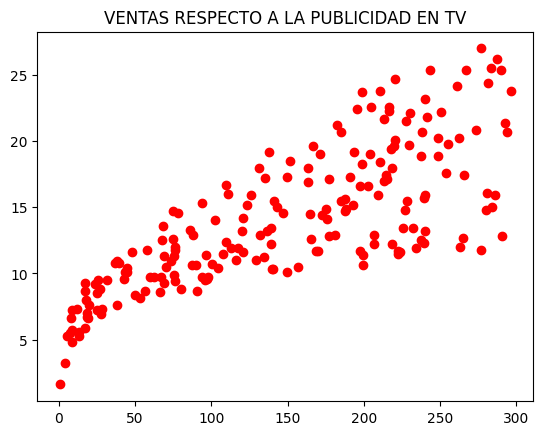

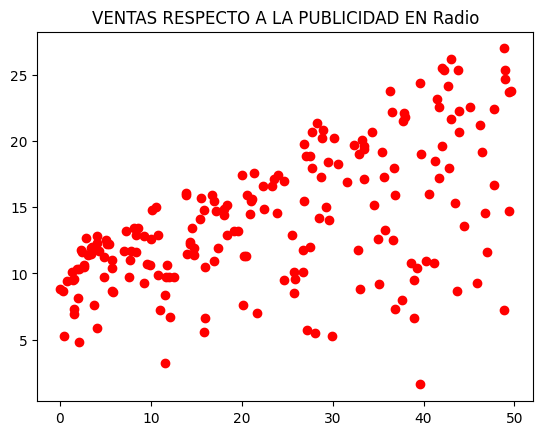

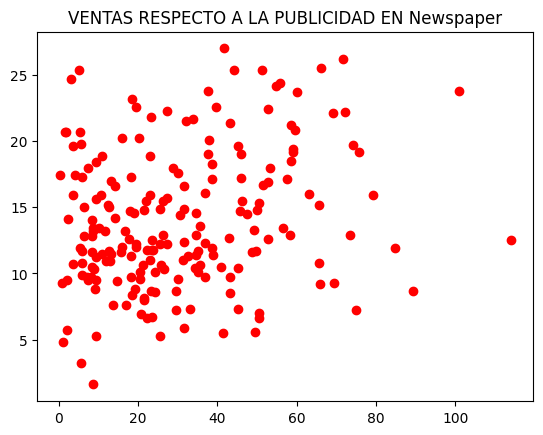

In [ ]:
#para graficar, utilizamos MATPLOTLIB
cols = ['TV', 'Radio', 'Newspaper']

for col in cols:
 plt.plot(data[col],data['Sales'],'ro')
 plt.title('VENTAS RESPECTO A LA PUBLICIDAD EN %s' %col)
 plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split #permite dividir el conjunto de datos en entrenamiento y validación
from sklearn.metrics import mean_squared_error, r2_score #permite calcular el error cuadrático medio (MSE)

In [ ]:
#variable independiente
#X = data['TV'].values
X = data['TV'].values.reshape(-1,1)

#VARIABLE DEPENDIENTE
Y = data['Sales'].values


In [ ]:
#dividir conj de datos entre entrenamiento y testing
X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
print(X_train.shape)
print(X_test.shape)

(160, 1)
(40, 1)


In [ ]:
#devuelve
 #(160, 1) #80% de datos para train
# (40, 1) #20% de datos para test

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train,Y_train)

LinearRegression()

In [ ]:
#primer modelo entrenado

In [ ]:
Y_pred = lin_reg.predict(X_test)

In [ ]:
Y_pred

array([14.71794394, 16.2115484 , 20.74819743,  7.66403631, 17.37013877,
       10.61402143, 17.2072847 ,  9.44612512, 17.46785121, 15.2669948 ,
        8.58532504,  9.73460946, 18.03086098,  7.37089899, 13.61053628,
       15.03899911,  7.45930549, 16.31391381, 10.62332738, 18.16579721,
       17.79821232, 10.27435438,  8.88776831, 18.79394862, 10.33019006,
        9.60897918, 17.05373658, 13.60123034, 11.17703121,  7.51048819,
       16.41627922, 10.339496  , 16.37440246,  7.90599093, 20.18053468,
       18.203021  ,  9.36702457, 19.85482655, 12.57292322,  8.39920611])

In [ ]:
#para ver qué tan bueno esd el modelo:
print('Predicciones: {}, Reales: {}'.format(Y_pred[:4],Y_test[:4]))

Predicciones: [14.71794394 16.2115484  20.74819743  7.66403631], Reales: [16.9 22.4 21.4  7.3]


In [ ]:
#No es demasiado bueno

#SI RMSE DA ERROR EJECUTAR !pip install --upgrade scikit-learn

In [ ]:
import numpy as np

#RMSE
mse = mean_squared_error(Y_test,Y_pred)
rmse = np.sqrt(mse)
print('RMSE: ',rmse)

#Para que fuese válido, el RMSE debería acercarse al valor mínimo de los datos de ventas
#Lo que no se cumple

#R2
r2 = r2_score(Y_test,Y_pred)
print('R2: ',r2)

#R2 va de 0 a 1
#R2 indica el nivel de acierto del modelo. 0.67 --> 67% DE ACIERTO

RMSE:  3.194472431998898
R2:  0.6766954295627076


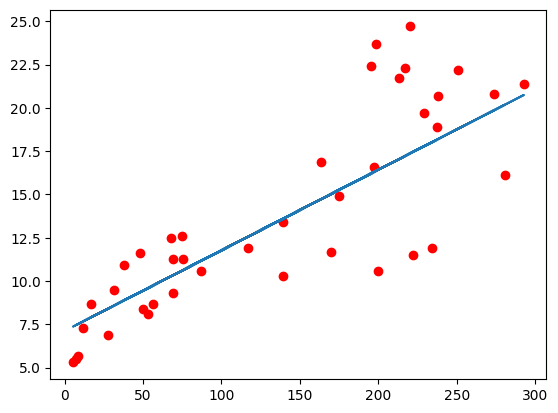

In [ ]:
plt.plot(X_test,Y_test,'ro')
plt.plot(X_test,Y_pred)
plt.show()

In [ ]:
#funcion que lo hace todo
def modelos_simple(independiente):
  #variable independiente
  #X = data['TV'].values
  X = data[independiente].values.reshape(-1,1)

  #VARIABLE DEPENDIENTE
  Y = data['Sales'].values
  #dividir conj de datos entre entrenamiento y testing
  X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

  #creo modelo de regresión:
  lin_reg = LinearRegression()
  lin_reg.fit(X_train,Y_train)

  #prediccion de valores
  Y_pred = lin_reg.predict(X_test)

  #para ver qué tan bueno esd el modelo:
  print('Predicciones: {}, Reales: {}'.format(Y_pred[:4],Y_test[:4]))

  import numpy as np

  #RMSE
  mse = mean_squared_error(Y_test,Y_pred)
  rmse = np.sqrt(mse)
  print('RMSE: ',rmse)

  #R2
  r2 = r2_score(Y_test,Y_pred)
  print('R2: ',r2)

  #grafico todo
  plt.plot(X_test,Y_test,'ro')
  plt.plot(X_test,Y_pred)
  plt.show()

Predicciones: [15.88332197 19.17427219 15.20877938 16.96667826], Reales: [16.9 22.4 21.4  7.3]
RMSE:  4.8216974799471926
R2:  0.2634309396999791


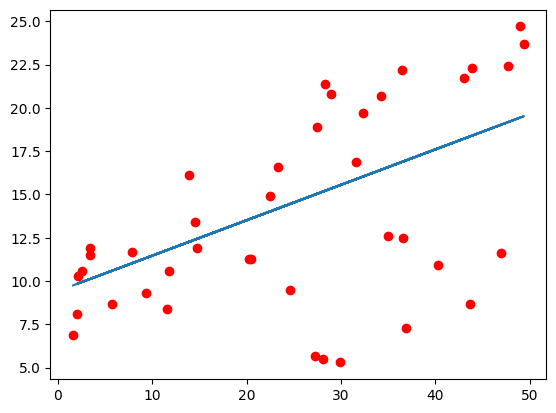

In [ ]:
modelos_simple('Radio')

In [ ]:
#ha subido el RMSE y bajado el R2, el modelo es mucho peor tomando en cuenta la RADIO

Predicciones: [15.47167765 15.47167765 14.89203768 15.01155108], Reales: [16.9 22.4 21.4  7.3]
RMSE:  5.533600454969853
R2:  0.029871749149522397


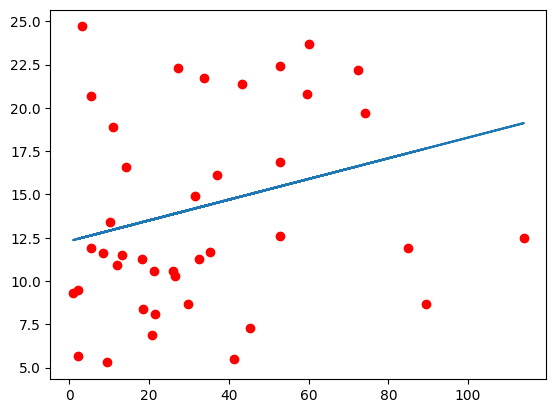

In [ ]:
modelos_simple('Newspaper')

In [ ]:
#Este es el peor de los modelos

==> Lo mejor para hacer la predicción son los datos de TV

In [ ]:
#solo hemos utilizado una variable para prdecir un valor, pero se pueden utilizar
# N variables para predecir un valor

## MODELO DE REGRESIÓN LINEAL MÚLTIPLE

In [ ]:
import seaborn as sns

Predicciones: [16.00205249 17.4873792  21.45480309  8.555338  ], Reales: [16.9 22.4 21.4  7.3]
RMSE:  3.3260422878644853
R2:  0.649515280538585


<Axes: >

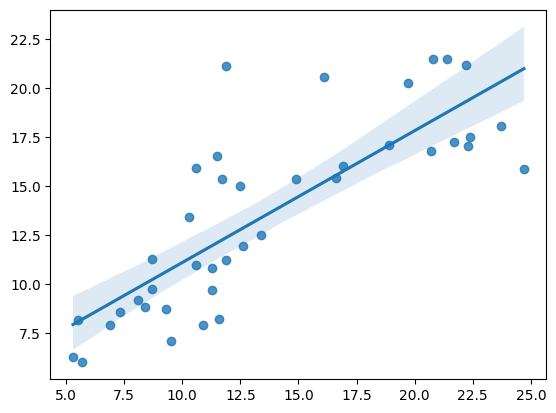

In [ ]:

#variables independientes
# voy a eliminar de la lista lo que no quiero
X = data.drop(['Radio','Sales'], axis = 1).values #axis = 1 elimina solo esas columnas

#VARIABLE DEPENDIENTE
Y = data['Sales'].values
#dividir conj de datos entre entrenamiento y testing
X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

#creo modelo de regresión:
lin_reg = LinearRegression()
lin_reg.fit(X_train,Y_train)

#prediccion de valores
Y_pred = lin_reg.predict(X_test)

#para ver qué tan bueno esd el modelo:
print('Predicciones: {}, Reales: {}'.format(Y_pred[:4],Y_test[:4]))

import numpy as np

#RMSE
mse = mean_squared_error(Y_test,Y_pred)
rmse = np.sqrt(mse)
print('RMSE: ',rmse)

#R2
r2 = r2_score(Y_test,Y_pred)
print('R2: ',r2)

#grafico todo
sns.regplot(x = Y_test, y = Y_pred )

In [ ]:
#vemos que Newspaper estropea el modelo

Predicciones: [16.35747252 20.86299397 21.52505848 10.58719845], Reales: [16.9 22.4 21.4  7.3]
RMSE:  1.7714254173033515
R2:  0.9005833101920356


<Axes: >

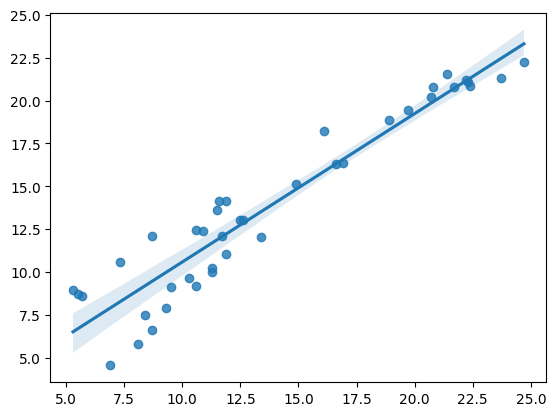

In [ ]:
#variables independientes
# voy a eliminar de la lista lo que no quiero
X = data.drop(['Newspaper','Sales'], axis = 1).values #axis = 1 elimina solo esas columnas

#VARIABLE DEPENDIENTE
Y = data['Sales'].values
#dividir conj de datos entre entrenamiento y testing
X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

#creo modelo de regresión:
lin_reg = LinearRegression()
lin_reg.fit(X_train,Y_train)

#prediccion de valores
Y_pred = lin_reg.predict(X_test)

#para ver qué tan bueno esd el modelo:
print('Predicciones: {}, Reales: {}'.format(Y_pred[:4],Y_test[:4]))

import numpy as np

#RMSE
mse = mean_squared_error(Y_test,Y_pred)
rmse = np.sqrt(mse)
print('RMSE: ',rmse)

#R2
r2 = r2_score(Y_test,Y_pred)
print('R2: ',r2)

#grafico todo
sns.regplot(x = Y_test, y = Y_pred )

In [ ]:
#Vemos que RADIO + TV es la mejor combinación, pues proporciona las mejores predicciones

REGRESIÓN POLINÓMICA


In [ ]:
# Creación del conjunto de datos
pos = [x for x in range(1,11)]
post = ["Pasante de Desarrollo",
 "Desarrollador Junior",
 "Desarrollador Intermedio",
 "Desarrollador Senior",
 "Líder de Proyecto",
 "Gerente de Proyecto",
 "Arquitecto de Software",
 "Director de Desarrollo",
 "Director de Tecnología",
 "Director Ejecutivo (CEO)"]
salary = [1200.0, 2500.0, 4000.0, 4800.0, 6500.0, 9000.0, 12820.0, 15000.0, 25000.0, 50000.0]



In [ ]:
# Creación del conjunto --> diccionario con la estructura general
data = {
    'position': post,
    'years': pos,
    'salary': salary
}

data = pd.DataFrame(data)
data.head()

,position,years,salary
0,Pasante de Desarrollo,1,1200.0
1,Desarrollador Junior,2,2500.0
2,Desarrollador Intermedio,3,4000.0
3,Desarrollador Senior,4,4800.0
4,Líder de Proyecto,5,6500.0


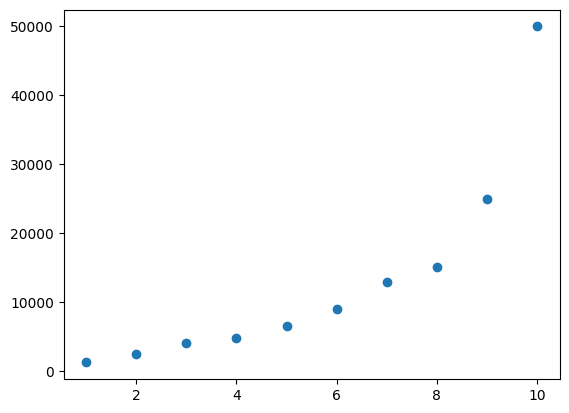

In [ ]:
plt.scatter(data['years'],data['salary'])
plt.show()

In [ ]:
#se ve como los datos no tienen una relación lineal (parece más exponencial)

In [ ]:
#si aplicamos regresión lineal va a haber mucho error

In [ ]:
X = data.iloc[:,1].values.reshape(-1,1) #pos 1 = años
Y = data.iloc[:,-1].values # saco la ultima columna (es una forma de hacerlo si no sabemos el tamaño)


In [ ]:
#no vamos a dividir el conjunto de datos
#utilizamos todos los valores para el entrenamiento pq son muy pocos datos

from sklearn.linear_model import LinearRegression
regression = LinearRegression()
regression.fit(X,Y)

LinearRegression()

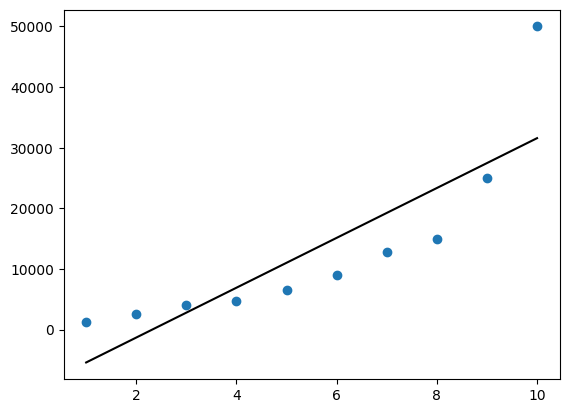

In [ ]:
#si graficamos el modelo
plt.scatter(data['years'],data['salary'])
plt.plot(X,regression.predict(X), color = 'black')
plt.show()

In [ ]:
#se ve que el modelo es muy malo

In [ ]:
#se deben tener en cuenta los grados del polinomio:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree = 4)
X_poly = poly.fit_transform(X)
X_poly = poly.fit_transform(X)
X_poly

array([[1.000e+00, 1.000e+00, 1.000e+00, 1.000e+00, 1.000e+00],
       [1.000e+00, 2.000e+00, 4.000e+00, 8.000e+00, 1.600e+01],
       [1.000e+00, 3.000e+00, 9.000e+00, 2.700e+01, 8.100e+01],
       [1.000e+00, 4.000e+00, 1.600e+01, 6.400e+01, 2.560e+02],
       [1.000e+00, 5.000e+00, 2.500e+01, 1.250e+02, 6.250e+02],
       [1.000e+00, 6.000e+00, 3.600e+01, 2.160e+02, 1.296e+03],
       [1.000e+00, 7.000e+00, 4.900e+01, 3.430e+02, 2.401e+03],
       [1.000e+00, 8.000e+00, 6.400e+01, 5.120e+02, 4.096e+03],
       [1.000e+00, 9.000e+00, 8.100e+01, 7.290e+02, 6.561e+03],
       [1.000e+00, 1.000e+01, 1.000e+02, 1.000e+03, 1.000e+04]])

In [ ]:
regression_2 = LinearRegression()
regression_2.fit(X_poly,Y)

LinearRegression()

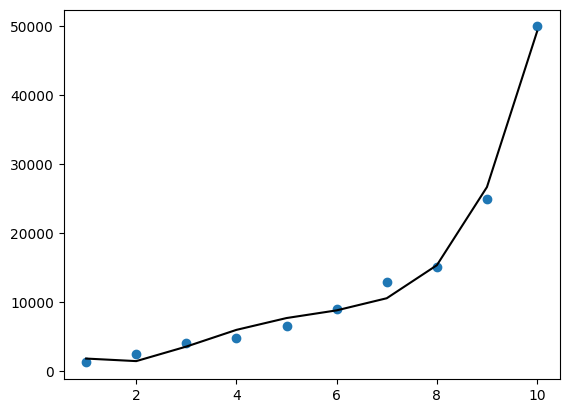

In [ ]:
#si graficamos el modelo
plt.scatter(data['years'],data['salary'])
plt.plot(X,regression_2.predict(X_poly), color = 'black')
plt.show()

In [ ]:
predict = poly.fit_transform([[2]])
regression_2.predict(predict)

array([1398.34498834])

In [ ]:
#vemos que es mucho más preciso

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
#para saber su precisión:
Y_pred = regression_2.predict(X_poly)

mse = mean_squared_error(Y,Y_pred)
rmse = np.sqrt(mse)
print('RMSE: ',rmse)

#R2
print('R2: ',r2_score(Y,Y_pred))

RMSE:  1148.1273188659534
R2:  0.9933186366907111


In [ ]:
#99% DE PRECISIÓN

## SVR -- support vector machine

PAra regresión

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv("/content/sample_data/Advertising.csv")
data.head()
data = data.iloc[:,1:] #selecciona todas las filas (:) y la columna 1 hasta la última
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
#la máquina de soporte vectorial tiene distintos kernel para distintas situaciones
#Para este caso, ayudamos al algoritmo "acompañando" a la recta de regresión con dos
#vectores paralelos a ella (vectores de soporte o apoyo)
#para modificar el error se modifica la distancia entre los vectores de soporte y la recta de regresión
#Esto genera el riesgo de tener un sobreajuste (nada bueno)

In [ ]:
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# tv - newspaper
#variables independientes
# voy a eliminar de la lista lo que no quiero
X = data.drop(['Radio','Sales'], axis = 1).values #axis = 1 elimina solo esas columnas

#VARIABLE DEPENDIENTE
Y = data['Sales'].values
#dividir conj de datos entre entrenamiento y testing
X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
svr = SVR() #por defecto kernel = RBF optimo para cuando la regresión no es lineal
svr.fit(X_train,Y_train)

SVR()

In [ ]:
y_pred = svr.predict(X_test)
print('REALES:', y_pred[:4])
print('PREDICCIONES:', Y_test[:4])

REALES: [15.92644542 17.19547972 18.032271    8.22924309]
PREDICCIONES: [16.9 22.4 21.4  7.3]


In [ ]:
r2_score(Y_test,y_pred)

0.6656952068341743

In [ ]:
#en regr lineal multimple teniamos 0.64 -- la maquina de soporte vectorial es más precisa pero la combinación TV-Newspaper no es la mejor

In [ ]:
svr = SVR(kernel='linear')
svr.fit(X_train,Y_train)
y_pred = svr.predict(X_test)
print('REALES:', y_pred[:4])
print('PREDICCIONES:', Y_test[:4])
r2_score(Y_test,y_pred)

REALES: [16.19274677 17.89164589 22.49658004  7.72850145]
PREDICCIONES: [16.9 22.4 21.4  7.3]


0.6433493803838424

In [ ]:
#este kernel no es lo mejor, mejor el RBF -- El modelo tampoco es lineal, así que es normal

In [ ]:
# tv - Radio
#variables independientes
# voy a eliminar de la lista lo que no quiero
X = data.drop(['Newspaper','Sales'], axis = 1).values #axis = 1 elimina solo esas columnas

#VARIABLE DEPENDIENTE
Y = data['Sales'].values
#dividir conj de datos entre entrenamiento y testing
X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)
svr = SVR(kernel='rbf')
svr.fit(X_train,Y_train)
y_pred = svr.predict(X_test)
print('REALES:', y_pred[:4])
print('PREDICCIONES:', Y_test[:4])
r2_score(Y_test,y_pred)

REALES: [16.25106175 19.54842936 18.32663294  8.51097891]
PREDICCIONES: [16.9 22.4 21.4  7.3]


0.8989271754336223

In [ ]:
#vemos que, como antes TV-RADIO es lo mejor (En reg lin mult sacaba 0.90, era algo mejor)

In [ ]:
# tv - Radio
#variables independientes
# voy a eliminar de la lista lo que no quiero
X = data.drop(['Newspaper','Sales'], axis = 1).values #axis = 1 elimina solo esas columnas

#VARIABLE DEPENDIENTE
Y = data['Sales'].values
#dividir conj de datos entre entrenamiento y testing
X_train , X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)
svr = SVR(kernel='linear')
svr.fit(X_train,Y_train)
y_pred = svr.predict(X_test)
print('REALES:', y_pred[:4])
print('PREDICCIONES:', Y_test[:4])
r2_score(Y_test,y_pred)

REALES: [16.73418803 21.37036229 21.56530583 11.37571112]
PREDICCIONES: [16.9 22.4 21.4  7.3]


0.8851634508666466

In [ ]:
#empeora con kernel lineal

## CALIFORNIA DATA


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
data = pd.read_csv('/content/sample_data/housing.csv')
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
#vemos que en totalbedrooms hay menos datos (20433 datos frente a 20640)

In [ ]:
data['ocean_proximity'].value_counts() # para ver un dato

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

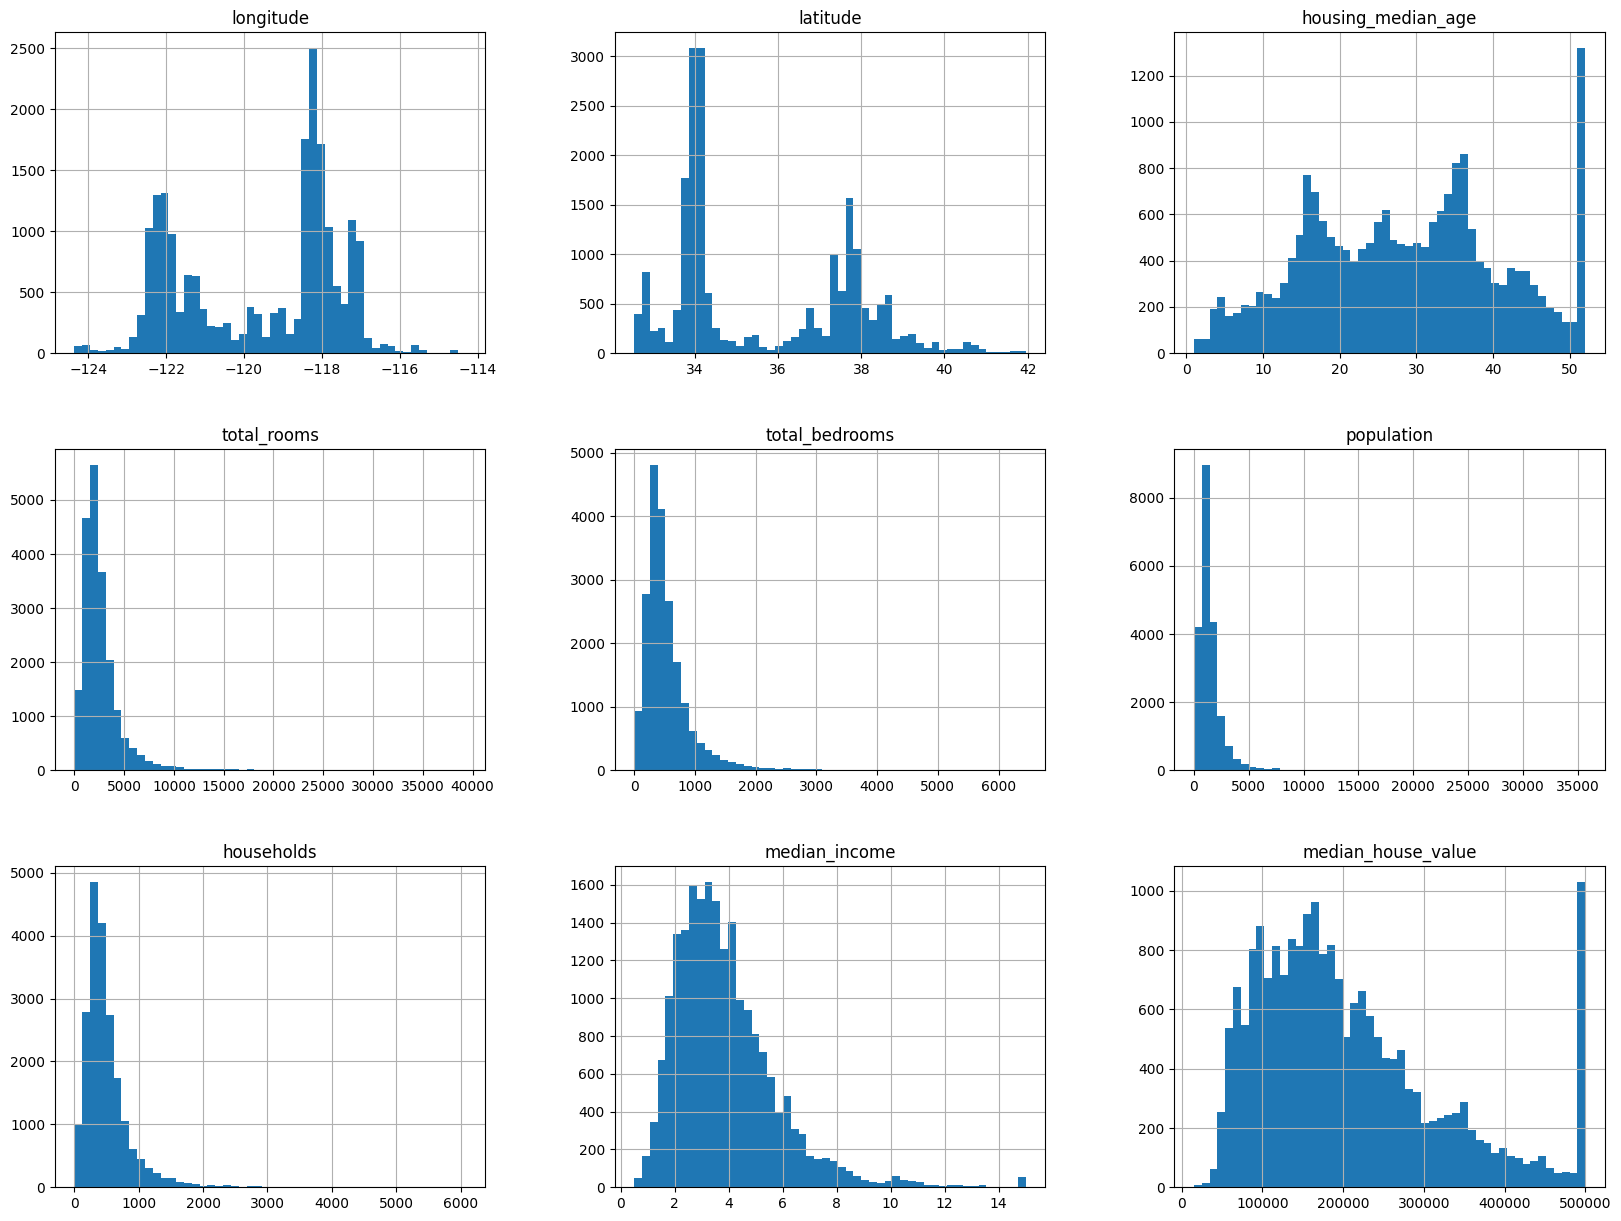

In [ ]:
data.hist(bins=50,figsize=(20,15)) #50 columnas del histograma y los 9 gráficos en una ventana de 20x15

In [ ]:
#latitud y longitud no son datos que se aprecien bien, son coordenadas
#muchas de las columnas de valores están "hacia un lado"
#una distribuciónm incorrecta de los datos puede afectar al rendimiento del algoritmo

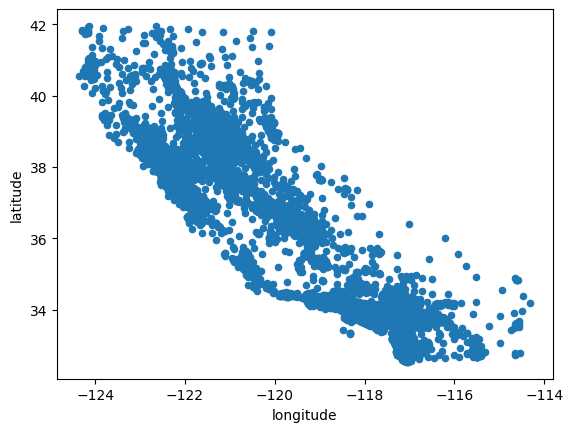

In [ ]:
data.plot(kind= 'scatter',x='longitude',y='latitude')
plt.show()

In [ ]:
#vemos como se dibuja el estado de California

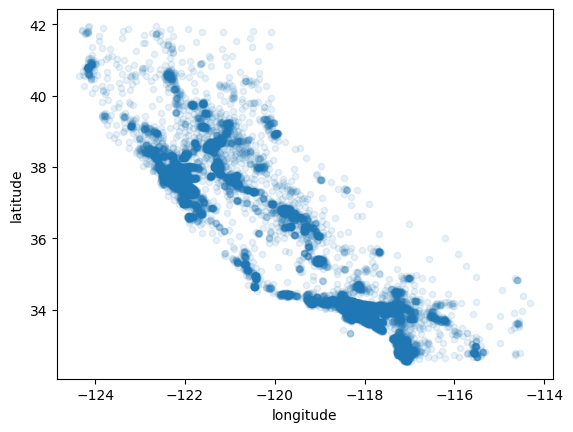

In [ ]:
data.plot(kind= 'scatter',x='longitude',y='latitude', alpha = 0.1) #dodne coincidan más ptos será mas oscuro
plt.show()

In [ ]:
#vemos que hay muchos ptos cerca del mar -- Puede ser un parámetro importante

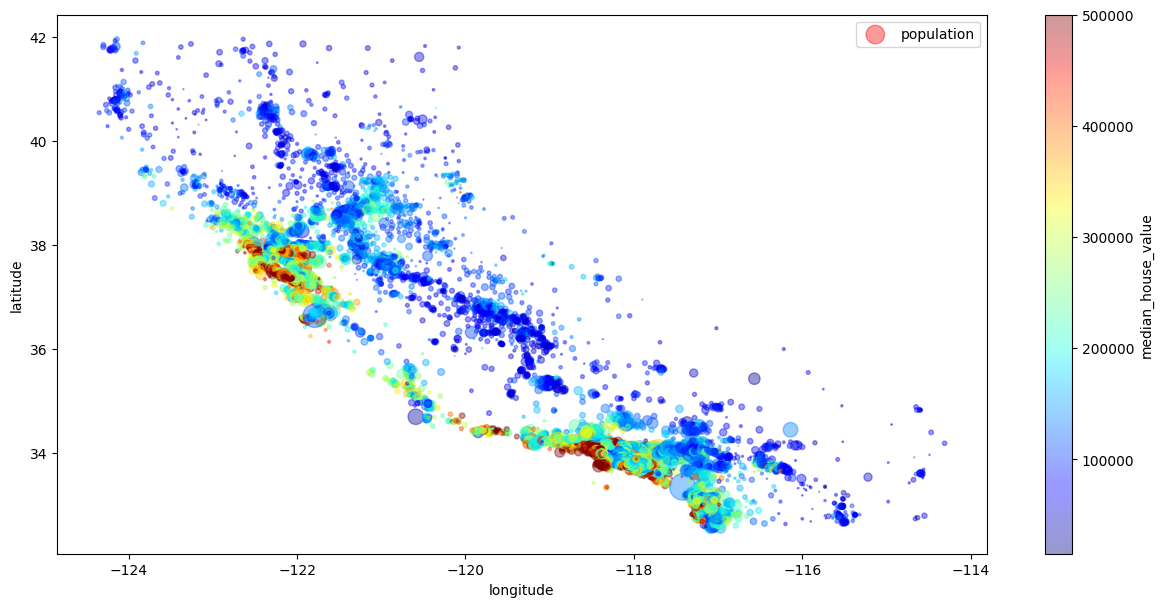

In [ ]:
data.plot(kind= 'scatter',x='longitude',y='latitude', alpha = 0.4, s = data['population']/100, label = 'population',
          figsize=(15,7), c = 'median_house_value', cmap= plt.get_cmap('jet')
          ,colorbar = True,) #define el tamaño de los ptos en función de la gente que hay en los hoteles
plt.legend()
plt.show()

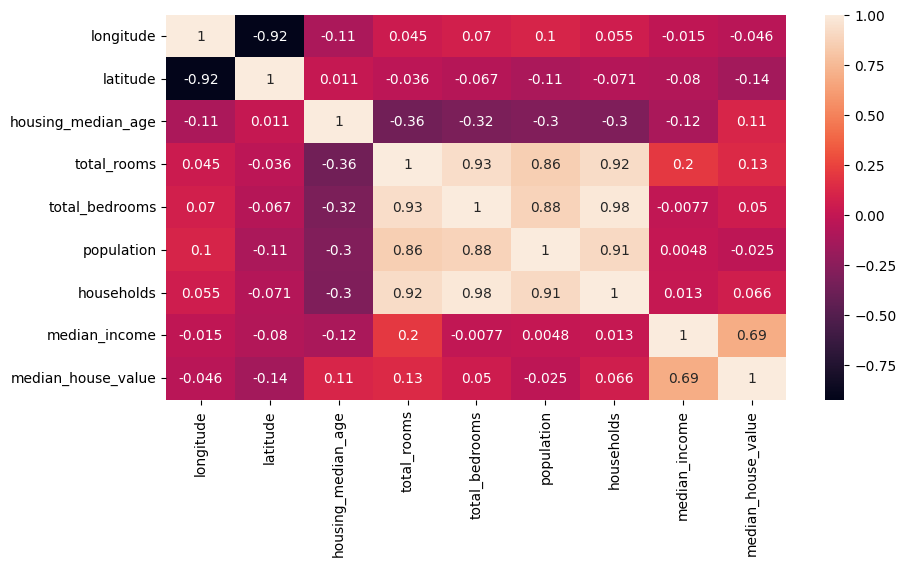

In [ ]:
#para ver el impacto de unas variables en otras utilizamos la correlación
plt.figure(figsize=(10,5))
#sns.heatmap(data.corr(), annot=True) da error pq la ultmia col no es numerica

sns.heatmap(data.iloc[:,:-1].corr(), annot=True)

#Esto quita la última columna "ocean_proximity"
#otra opción sería despreciar datos no numéricos:

#numeric_data = data.select_dtypes(include=['float64', 'int64'])

plt.show()

In [ ]:
#la variable a predecir es "median_house_value"
#hay que ver cómo las demás columnnas se relacionan con ella
#la variable con mayor correlación a la buscada es "median income"
#las coordenadas tienen correlación muy negativa -- no tienen influencia
# justo lo contrario a lo que pensábamos antes

In [ ]:
corr_matrix = data.iloc[:,:-1].corr()
corr_matrix['median_house_value'].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


### combinacion de atributos

- 'rooms_per_household' : num medio de habitaciones por hogar en una cierta area. Proporciona una medida de densidad de habitaciones en una vivendia promedio en esa área

- 'bedrooms_per_room' : Indica la proporción de dormitorios con respecto al num total de habitaciones en una cierta área.

- 'bedrooms_per_household' : densidad de población promedio por hogar en una cierta área

In [ ]:
data['rooms_per_household'] = data['total_rooms'] / data['households']
data['bedrooms_per_room'] = data['total_bedrooms'] / data['total_rooms']
data['population_per_household'] = data['population'] / data['households']

In [ ]:
numeric_data = data.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_data.corr()
corr_matrix['median_house_value'].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688075
rooms_per_household,0.151948
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population_per_household,-0.023737
population,-0.024650
longitude,-0.045967


In [ ]:
#rooms_per_household es la mejor de las 3 pero tampoco es que destaque mucho

In [ ]:
# a partir de aquí, podemos empezar a trabajar sobre el conjunto

In [ ]:
# a total bedrooms le faltaban datos -- debemos rellenar con datos que no afecten al rendimiento

### Limpieza de datos y manejo de atributos categóricos

In [ ]:
#rellenar info que falta
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20433 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  object 
 10  rooms_per_household       20640 non-null  float64
 11  bedrooms_per_room         20433 non-null  float64
 12  population_per_household  20640 non-null  float64
dtypes: float64(12), object(1)
memory usage: 2.0+ MB


In [ ]:
# a la hora d erellenar hay que tener mucho cuidado de con qué valores se hace
# si rellenamos con 0s y más alante queremos hacer cáculos con esos valores
#p ej. la media, esos valores = 0 van a afectar en nuestros cálculos
data['total_bedrooms'].fillna(data['total_bedrooms'].median(), inplace = True)
data.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20640 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  object 
 10  rooms_per_household       20640 non-null  float64
 11  bedrooms_per_room         20433 non-null  float64
 12  population_per_household  20640 non-null  float64
dtypes: float64(12), object(1)
memory usage: 2.0+ MB


/tmp/ipykernel_2211/291912174.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['total_bedrooms'].fillna(data['total_bedrooms'].median(), inplace = True)


In [ ]:
#manipulación de datos categóricos --> Pasar a numero los datos de la columna 'ocean_proximity'
#hay más de una forma de hacerlo
from sklearn.preprocessing import OrdinalEncoder
data_ocean = data[['ocean_proximity']] #se extrae dentro de una lista para que no lo extraiga como un array
ordinal_encoder = OrdinalEncoder()
data_ocean_encoded = ordinal_encoder.fit_transform(data_ocean)

In [ ]:
np.random.choice(data_ocean_encoded.ravel(), size = 10)

array([4., 0., 1., 1., 3., 0., 1., 1., 0., 1.])

In [ ]:
#vemos cómo la información categórica se ha transformado en datos numéricos
#que ya podemos manejar y utilizar en el algoritmo de regresión

In [ ]:
#tenemos valores del 0 al 4 --> 5 valores
#esta distribución de datos puede afectar al rendimiento del algoritmo de regresión
#además, al ser datos categóricos, no se pueden sumar entre si
#imaginemos 'pera' = 1 y 'limon' = 3, aunque se han transformado cadenas de caracteres
# en números, seguimos sin poder sumar limones y peras
#además, el algoritmo se puede llegar a pensar que p. ej. 0 y 1 son cercanos y que 0 y 4 son lejanos
# cuando no tiene nada que ver, la información se debe tratar de una forma distinta
# pues son cosas que no tienen que ver entre sí.

In [ ]:
# una mejor forma de tratar la información categórica y que no afecte al
#rendimiento del algoritmo sería:

In [ ]:
from sklearn.preprocessing import OneHotEncoder
#se van a crear variables dummy que nos permitirán tratar la información categórica
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(data_ocean)


In [ ]:
data_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       ...,
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

In [ ]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [ ]:
#crea arrays donde por ejemplo, el primero es 0.0.0.1.0. (indica posición = 3 --> 'NEAR BAY')
#La segunda que aparece (realmente es el ultimo dato) es 0.1.0.0.0. (posicion = 1 --> 'INLAND')

#esta info hay que pasarla a un dataFrame para poder entrenar nuestro algoritmo

In [ ]:
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns=cat_encoder.get_feature_names_out())

encoded_df.head()

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,1.0,0.0


### Crear los algoritmos de Machine Learning

In [ ]:
# Variable dependiente e independientes
#dependiente
y = data['median_house_value'].values.reshape(-1,1)


In [ ]:
#dependientes
X = data[[
    'median_income',
    'rooms_per_household',
    'total_rooms',
    'housing_median_age',
    'households'
]]
# estas son las variables que más pesaban en la correlación

In [ ]:
#como también hemos creado unas columnas basadas en OCEAN PROXIMITY, las vamos a utilizar
data1 = pd.concat([X,encoded_df],axis = 1)
data1.columns

Index(['median_income', 'rooms_per_household', 'total_rooms',
       'housing_median_age', 'households', 'ocean_proximity_<1H OCEAN',
       'ocean_proximity_INLAND', 'ocean_proximity_ISLAND',
       'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN'],
      dtype='object')

In [ ]:
X = data1.values

### Regresión lienal múltiple

In [ ]:
from sklearn.model_selection import train_test_split


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:

print(X_train.shape)
print(y_train.shape)

(16512, 10)
(16512, 1)


In [ ]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

LinearRegression()

In [ ]:
#ya tenemos el algoritmo de regresión múltiple

In [ ]:
y_pred = lin_reg.predict(X_test)

In [ ]:

from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
r2

0.6052577349795184

In [ ]:
data1.head()

,median_income,rooms_per_household,total_rooms,housing_median_age,households,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,8.3252,6.984127,880.0,41.0,126.0,0.0,0.0,0.0,1.0,0.0
1,8.3014,6.238137,7099.0,21.0,1138.0,0.0,0.0,0.0,1.0,0.0
2,7.2574,8.288136,1467.0,52.0,177.0,0.0,0.0,0.0,1.0,0.0
3,5.6431,5.817352,1274.0,52.0,219.0,0.0,0.0,0.0,1.0,0.0
4,3.8462,6.281853,1627.0,52.0,259.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
#vemos que los valores numéricos van de valores muy altos a muy bajos (7000 a 1)
#esta diferencia puede afectar al algoritmo de regresión
#para solucionarlo, podemos utilizar el "escalado de variables" -->solo se aplica a las variables independientes (nunca a la de salida / dependiente)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X = sc_X.fit_transform(X)

In [ ]:
#NECESITAMOS VOLVER A ENTRENAR EL ALGORITMO
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)
r2 = r2_score(y_test, y_pred)
r2

0.6083708326453947

In [ ]:
#NO HUBO UNA MEJORA IMPORTANTE PERO ES IMPORTANTE SABER ESCALAR LOS DATOS

In [ ]:
#AHORA VAMOS A AGREGAR LAS VARIABLES DE LONGITUD Y LATITUD PARA VER SI SON SIGNIFICATIVOS

# Creación del modelo columna por columna --> COGEMOS LO ANTERIOR Y AÑADIMOS LATITUD Y LONG
columnas = ['median_income', 'rooms_per_household','total_rooms','housing_median_age','households', 'latitude', 'longitude']
col_modelo = []
y = data['median_house_value'].values.reshape(-1,1)

for col in columnas:
  col_modelo.append(col)
  data1 = data[col_modelo]
  data1 = pd.concat([data1, encoded_df], axis=1)
  X = data1.values

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
  lin_reg = LinearRegression()
  lin_reg.fit(X_train, y_train)
  y_pred = lin_reg.predict(X_test)
  r2 = r2_score(y_test, y_pred)
  print(col_modelo, r2)

['median_income'] 0.5676690700796501
['median_income', 'rooms_per_household'] 0.5749048973241075
['median_income', 'rooms_per_household', 'total_rooms'] 0.5855154325302923
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age'] 0.6116879093031666
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households'] 0.6066478382235192
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households', 'latitude'] 0.6145197817434106
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households', 'latitude', 'longitude'] 0.6123673866657239


In [ ]:
#De esta forma vemos como cambia el rendimiento según las categorías que se van añadiendo
#también se ve como al añadir las coordenadas, aumenta la calificación del algoritmo (63%)

## Árbol de regresión

In [ ]:
from sklearn.tree import DecisionTreeRegressor


In [ ]:
#para arboles y bosques aleatorios no es necesario el escalado de datos

In [ ]:
columnas = ['median_income', 'rooms_per_household','total_rooms','housing_median_age','households', 'latitude', 'longitude']
col_modelo = []
y = data['median_house_value'].values.reshape(-1,1)

for col in columnas:
  col_modelo.append(col)
  data1 = data[col_modelo]
  data1 = pd.concat([data1, encoded_df], axis=1)
  X = data1.values

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
  tree_reg = DecisionTreeRegressor()
  tree_reg.fit(X_train, y_train)
  y_pred = tree_reg.predict(X_test)
  r2 = r2_score(y_test, y_pred)
  print(col_modelo, r2)

['median_income'] 0.3079149629817405
['median_income', 'rooms_per_household'] 0.2016123380816397
['median_income', 'rooms_per_household', 'total_rooms'] 0.22324878488580724
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age'] 0.3193270904920591
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households'] 0.28540807047197114
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households', 'latitude'] 0.39950023291120573
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households', 'latitude', 'longitude'] 0.6384823546222228


In [ ]:
#vemos queno hay un cambio considerable

## Bosque aleatorio

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
columnas = ['median_income', 'rooms_per_household','total_rooms','housing_median_age','households', 'latitude', 'longitude']
col_modelo = []
y = data['median_house_value'].values

for col in columnas:
  col_modelo.append(col)
  data1 = data[col_modelo]
  data1 = pd.concat([data1, encoded_df], axis=1)
  X = data1.values

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
  forest_reg = RandomForestRegressor()
  forest_reg.fit(X_train, y_train)
  y_pred = forest_reg.predict(X_test)
  r2 = r2_score(y_test, y_pred)
  print(col_modelo, r2)

['median_income'] 0.46236261560720837
['median_income', 'rooms_per_household'] 0.5564633007429721
['median_income', 'rooms_per_household', 'total_rooms'] 0.5946807096704567
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age'] 0.6328464422139228
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households'] 0.6521984030409913
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households', 'latitude'] 0.7308844376236219
['median_income', 'rooms_per_household', 'total_rooms', 'housing_median_age', 'households', 'latitude', 'longitude'] 0.831796714836163


In [ ]:
#VEMOS QUE EL RESULTADO INCREMENTA MUCHO, CASI UN 0.2 MÁS (UN 20% MEJOR)
# EL COSTE A PAGAR ES EL TIEMPO DEDICADO A ENTRENAR EL ALGORITMO
#PASAMOS DE 2 SEG A 1 MIN --> DEBEMOS SER CUIDADOSOS EN EL ALGORITMO QUE ELEGIMOS
# SIEMPRE ADAPTAR EL ALGORITMO A LA COMPLEJIDAD DE LOS DATOS

## CON ESTO, YA HEMOS VISATO TODOS LOS ALGORITMOS DE REGRESIÓN DISPONIBLES


# Algoritmos de Clasificación

## Problema de "Hola Mundo"
MNIST

In [ ]:
# conjunto de imágenes con números escritos a mano

In [ ]:
#para este ejemplo, vamos a utilizar el número 5

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', version=1)

In [ ]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [ ]:
#solo vamos a utilizar DATA (almacena el conjunto de las imágenes) y
# TARGET (Almacena el número al cuál hace referencia cada una de las imágenes

X, y = mnist['data'], mnist['target']
print(X.shape)
print(y.shape)

(70000, 784)
(70000,)


In [ ]:
#tenemos un conjunto de datos de 70000 imágenes (algo mediano) y 784 Características
# o lo que es lo mismo, cada imagen tiene 784 píxeles (28x28) de valor de 0 a 255


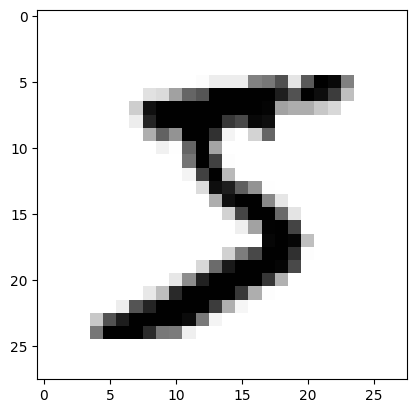

In [ ]:
#sacamos la imagen 0
digit = X.to_numpy()[0]

# transformamos la info
digit_image = digit.reshape(28,28) # queremos que todos los datos se transformen en tamaño 28x28

plt.imshow(digit_image,cmap='binary')
plt.show()

In [ ]:
#vemos un "5"

In [ ]:
#para comprobar que estamos viendo un 5
y = y.astype(np.uint8)
y[0]


np.uint8(5)

In [ ]:
# un algoritmo se puede ver afectado por el orden de la info que se le está enviando
# en este caso, el conjunto de mnsit puede tener 8000 "0", 2000 "1"
#el tener tantas veces el mismo num repetido, puede afectar al rendimiento del algoritmo
#ya que muchas veces se va a topar con el mismo num--> Lo que puede afectar al entrenamiento
#se deben aleatorizar los numeros de la forma correcta
#para este conjunto, ya están aleatorizados


In [ ]:
#para este conjunto utilizaremos 60000 datos para train y 10000 para validación
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

# [:60000] --> de 0 a 59999
# [60000:] --> de 60000 a 70000
# resumen --> [inicio : fin]

In [ ]:
#vamos a entrenar el algoritmo para que nos diga si la imagen es o no un "5"
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

In [ ]:
# algoritmo --> SGDClassifier
# vamos a enviarle 60000 imágenes con 780px cada una. Tiene que leer la info de cada px
# es por eso que se utiliza SGD, porque permite manejar un gran número de datos

from sklearn.linear_model import SGDClassifier
sgd_classifier = SGDClassifier(random_state=42)
sgd_classifier.fit(X_train, y_train_5)

SGDClassifier(random_state=42)

In [ ]:
#vamos a verificar cómo funciona.
#Sabemos que, en la primera posición, tenemos un 5 (lo verificamos antes)

sgd_classifier.predict([digit])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SGDClassifier was fitted with feature names
  warnings.warn(


array([ True])

In [ ]:
# el output es >> array([ True])
#SE DETECTA, EFECTIVAMENTE, QUE EL NUMERO EN POS = 0 ES UN 5

### Medir el rendimiento

In [ ]:
from sklearn.model_selection import cross_val_score
cross_val_score(sgd_classifier, X_train, y_train_5, cv=3, scoring='accuracy')
#cv = 3 --> Se divide el conjunto de entrenamiento en 3 partes y en cada una se califica qué tan bueno es el modelo

array([0.95035, 0.96035, 0.9604 ])

### Matriz de confusión

|||
|--|--|
|TN|FP|
|FN|TP|

In [ ]:
#en los algoritmos de clasificación existen muchos otros métodos para ver qué tan buenos son
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(sgd_classifier, X_train, y_train_5, cv=3)

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_train_5, y_train_pred)

array([[53892,   687],
       [ 1891,  3530]])

In [ ]:
# <> --> "Distinto de"
# 53892 veces le pasaron un numero <> de 5 y lo detectó cómo <> 5
# 687 veces le pasamos un num <> de 5 y lo detectó como 5
# 1891 veces se le pasó un 5 y detectó que era <> de 5
# 3530 veces se le pasó un 5 y detectó un 5


# lo importante aquí es que dónde más falla es en los Falsos Negativos (FN)
# Esto nos indica que el algoritmo no es muy preciso a la hora de detactar el num 5

In [ ]:
#Otras variables para medir el rendimiento son PRECISIÓN y MEMORIA (recall)

$$
precision = \frac{TP}{TP + FP}
$$

*TP* es el número de verdaderos positivos, y *FP* es el número de falsos positivos.

$$
recall = \frac{TP}{TP+FN}
$$

*FN* es el número de falsos positivos.


In [ ]:
from sklearn.metrics import precision_score, recall_score
precision_score(y_train_5, y_train_pred)
print(precision_score(y_train_5, y_train_pred))
recall_score(y_train_5, y_train_pred)
print(recall_score(y_train_5, y_train_pred))

0.8370879772350012
0.6511713705958311


In [ ]:
# se ve una precisión de un 83.71% (porcentaje de aciertos)
# y una memoria de 65.11% (qué tan bueno es el algoritmo para detectar el numero 5)

In [ ]:
# Se podría aumentar el rendimiento, pero sólo de un lado, es decir, o subimos el recall o la precisión,
# a medida que una sube, la otra baja
# para entender cuál mejorar, se debe entender la situación que queremso abordar

In [ ]:
#otra métrica es el F1 --> Le da más peso a la memoria que a la precisión (al valor más pequeño)

$$
F_1 = \frac{2}{\frac{1}{precision} + \frac{1}{recall}} = 2 * \frac{precision * recall}{precision + recall} = \frac{TP}{TP + \frac{FN + FP}{2}}
$$

In [ ]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred)

0.7325171197343847

In [ ]:
#el F1 es de 73.25%

## Regresión logística  -- Función Sigmoide

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [ ]:
#dividimos en variables dependientes e independientes

X = data.iloc[:,[2,3]]
y = data.iloc[:,-1].values

In [ ]:
#manejo de la variable categórica (Gender)
gender = data[['Gender']]

In [ ]:
#transformamos a valores numéricos
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(gender)

In [ ]:
cat_encoder.categories_

[array(['Female', 'Male'], dtype=object)]

In [ ]:
import numpy as np

data_cat_1hot
data_cat_1hot.toarray()[:3] #veo lo que hay en las 3 primeras filas

array([[0., 1.],
       [0., 1.],
       [1., 0.]])

In [ ]:
#vemos que las variables categóricas se han convertido en numeros

In [ ]:
#si transformamos toda la info a un DataFrame que podamos utilizar
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns = cat_encoder.get_feature_names_out())
encoded_df.head()

,Gender_Female,Gender_Male
0,0.0,1.0
1,0.0,1.0
2,1.0,0.0
3,1.0,0.0
4,0.0,1.0


In [ ]:
data1 = pd.concat([X, encoded_df], axis = 1) #axis = 1 inserta columnas
data1.head()

,Age,EstimatedSalary,Gender_Female,Gender_Male
0,19,19000,0.0,1.0
1,35,20000,0.0,1.0
2,26,43000,1.0,0.0
3,27,57000,1.0,0.0
4,19,76000,0.0,1.0


In [ ]:
data1.shape

(400, 4)

In [ ]:
#dividimos en train y test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(data1, y, test_size = 0.2,random_state=0)

In [ ]:
#comprobamos cuántos datos tenemos para entrenamiento y validación
print(X_train.shape)
print(X_test.shape)

(320, 4)
(80, 4)


In [ ]:
# en el campo de salarios, tenemos valores muy dispares y distantes entre si, por lo que
# va a ser necesario un escalado de la variables, reduciendo así la diferencia de datos
# y obtener mejores resultados en el algoritmo

# RECORDAR QUE SIEMPRE SE HACE EL ESCALADO EN LAS VARIABLES INDEP (X), NUNCA EN LA DEPENDIENTE (Y)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)

In [ ]:
#ya se puede entrenar el algoritmo

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
log_reg = LogisticRegression(random_state=0)
log_reg.fit(X_train, y_train)

LogisticRegression(random_state=0)

In [ ]:
y_pred = log_reg.predict(X_test)

In [ ]:
#si comparamos los 10 primeros valores reales con los 10 primeros predichos:
print('Reales', y_test[:10], 'Predicción', y_pred[:10])

Reales [0 0 0 0 0 0 0 1 0 0] Predicción [0 0 0 0 0 0 0 1 0 1]


In [ ]:
#vemos que solo se equivoca en el ultimo valor

#si queremos evaluar el rendimiento del algoritmo de clasificación -- MATRIZ DE CONFUSION

|||
|--|--|
|TN|FP|
|FN|TP|


In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[56,  2],
       [ 5, 17]])

In [ ]:
#si sacamos precisión, recall y F1
from sklearn.metrics import precision_score, recall_score, f1_score
print('Precisión: ',precision_score(y_test, y_pred))
print('Memoria: ', recall_score(y_test, y_pred))
print('F1: ', f1_score(y_test, y_pred))


Precisión:  0.8947368421052632
Memoria:  0.7727272727272727
F1:  0.8292682926829268


In [ ]:
#vemos una precisión más alta que la memoria y un F1 bastante alto 82.93%

## KNN -- K vecinos próximos


In [ ]:
# Calcula la distancia al punto del conjunto de datos y se queda con la más cercana para la predicción.
#se utilizan distintas ecuaciones para medir distancias
#EUCLIDIANA
#Manhattan
#Minkowski

#El uso de una u otra ecuación depende del problema al que nos enfrentemos

# se debe indicar el numero de vecinos que se evaluen en el cálculo de la predicción
#este algoritmo es muy bueno para conjunto de datos pequeños, con un gran número de datos su rendimiento
# no es el mejor, pues se tiene que poner a calcular muchas distancias

In [ ]:
import pandas as pd
data = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [ ]:
#dividimos en variables dependientes e independientes

X = data.iloc[:,[2,3]]
y = data.iloc[:,-1].values



In [ ]:
#manejo de la variable categórica (Gender)
gender = data[['Gender']]



In [ ]:
#transformamos a valores numéricos
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(gender)




In [ ]:

cat_encoder.categories_


[array(['Female', 'Male'], dtype=object)]

In [ ]:
data_cat_1hot
data_cat_1hot.toarray()[:3] #veo lo que hay en las 3 primeras filas

array([[0., 1.],
       [0., 1.],
       [1., 0.]])

In [ ]:

#si transformamos toda la info a un DataFrame que podamos utilizar
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns = cat_encoder.get_feature_names_out())
encoded_df.head()

data1 = pd.concat([X, encoded_df], axis = 1) #axis = 1 inserta columnas
data1.head()

,Age,EstimatedSalary,Gender_Female,Gender_Male
0,19,19000,0.0,1.0
1,35,20000,0.0,1.0
2,26,43000,1.0,0.0
3,27,57000,1.0,0.0
4,19,76000,0.0,1.0


In [ ]:
#dividimos en train y test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(data1, y, test_size = 0.2,random_state=0)


In [ ]:
#escalado de las variables
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(metric='minkowski', p=1)
knn.fit(X_train, y_train)

KNeighborsClassifier(p=1)

In [ ]:
y_pred = knn.predict(X_test)

In [ ]:
#si comparamos los 10 primeros valores reales con los 10 primeros predichos:
print('Reales', y_test[:10], 'Predicción', y_pred[:10])

Reales [0 0 0 0 0 0 0 1 0 0] Predicción [0 0 0 0 0 0 0 1 0 1]


In [ ]:
# Rendimiento muy parecido a la Regresión logística

Matriz de confusión


|||
|--|--|
|TN|FP|
|FN|TP|


In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[55,  3],
       [ 1, 21]])

In [ ]:
#si sacamos precisión, recall y F1
from sklearn.metrics import precision_score, recall_score, f1_score
print('Precisión: ',precision_score(y_test, y_pred))
print('Memoria: ', recall_score(y_test, y_pred))
print('F1: ', f1_score(y_test, y_pred))

Precisión:  0.875
Memoria:  0.9545454545454546
F1:  0.9130434782608695


In [ ]:
#vemos que el clasificador es mucho mejor que la regresión logística, a pesar de perder
#algo de precisión.

# La regresión logística tenía:

#Precisión:  0.8947368421052632
#Memoria:  0.7727272727272727
#F1:  0.8292682926829268


#Según el objetivo del problema, según si necesitamos mayor memoria o precisión, se
#eligirá uno u otro modelo.

## SVR
Para Clasificación


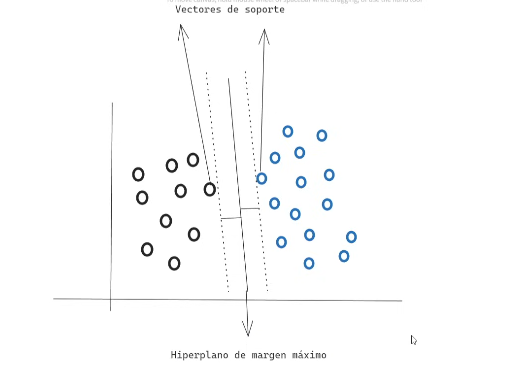

Para solventar casos como el siguiente, existen distintos tipos de Kernel que nos pueden ayudar

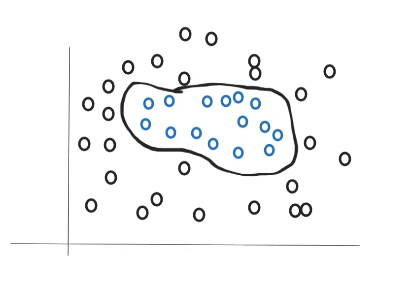


Cada uno de estos Kernel lleva implícita una matemática compleja asociada.

No es importante (a priori) saber toda esa matemática, pero sí es importante saber que existen varios tipos de kernel y conocer alguno.

Ventajas y desventajas

**Ventajas**

  1.Efectiva en espacios de características de alta dimensión: Puede manejar eficientemente conjuntos de datos con un gran número de características.

  2.Robusto ante espacios de características no lineales.

  3.Eficiente en memoria.

**Desventajas**

  1.sensibilidad a la escala y al ruido.

  2.Elección del kernel y parámetros.

  3.Dificultad con conjuntos de datos muy grandes.

In [ ]:
import pandas as pd

#cargar conjunto y sacar variables dep e indep
data = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')
X = data.iloc[:, [2, 3]]
y = data.iloc[:, -1].values
gender = data[['Gender']]

#manejo de la variable categórica (Gender)
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(gender)
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns = cat_encoder.get_feature_names_out())
data1 = pd.concat([X, encoded_df], axis = 1)

#division en train y test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


#escalado de variables
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)

#Usamos máquina de soporte vectorial (probamos con Kernel lineal)
from sklearn.svm import SVC
cls = SVC(kernel='linear', random_state=0)
cls.fit(X_train, y_train)


#sacamos la predicción
y_pred = cls.predict(X_test)

#evaluación del rendimiento
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import precision_score, recall_score
print('Precision:',precision_score(y_test, y_pred))
print('Recall:',recall_score(y_test, y_pred))

from sklearn.metrics import f1_score
print('F1:',f1_score(y_test, y_pred))

[[66  2]
 [ 8 24]]
Precision: 0.9230769230769231
Recall: 0.75
F1: 0.8275862068965517


In [ ]:
# vemos que se tiene una buena precisión pero no tan buena memoria
#el F1 no es mejor que en el caso anterior

In [ ]:
# si porbamos otros kernel como el RBF

cls = SVC(kernel='rbf', random_state=0)
cls.fit(X_train, y_train)
y_pred = cls.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print('Precision:',precision_score(y_test, y_pred))
print('Recall:',recall_score(y_test, y_pred))
print('F1:',f1_score(y_test, y_pred))

[[64  4]
 [ 3 29]]
Precision: 0.8787878787878788
Recall: 0.90625
F1: 0.8923076923076924


In [ ]:
#Vemos que baja la precisión pero baja la memoria significativamente
#El F1 ha aumentado también

In [ ]:
# con un Kernel Polinómico

cls = SVC(kernel='poly', random_state=0)
cls.fit(X_train, y_train)
y_pred = cls.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print('Precision:',precision_score(y_test, y_pred))
print('Recall:',recall_score(y_test, y_pred))
print('F1:',f1_score(y_test, y_pred))

[[67  1]
 [13 19]]
Precision: 0.95
Recall: 0.59375
F1: 0.7307692307692307


In [ ]:
#Aumenta precisión pero baja la memoria mucho
#El F1 se ve muy perjudicado

## Naive Bayes

Es un algoritmo de clasificación probabilística basado en el teorema de Bayes, que asume independencia condicional entre las características dadas las clases.

Este algoritmo es adecuado cuando:

· **Suposición de independencia es razonable**; Naive Bayes asume que las características de los datos son independientes entre sí. Esta suposición puede no ser realista en algunos casos, pero puede simplificar la aplicación del algoritmo.

· Cuando los **datos son multidimensionales**.

·Conjuntos de datos de **tamaño moderado a grande.**

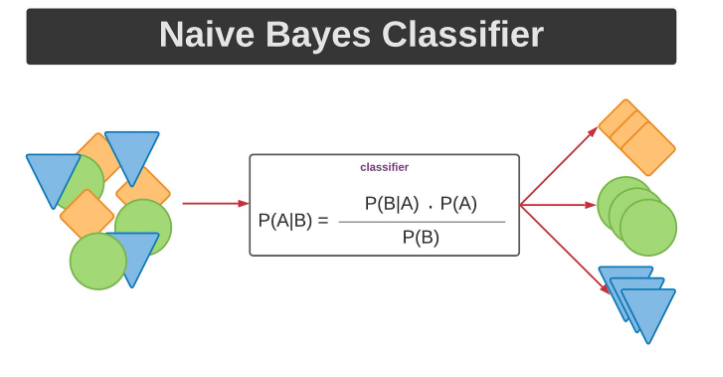

Ventajas

· Simple y eficiente.

·Buen rendimiento en conjuntos de datos textuales. Funciona especialmente bien en conjuntos de datos textuales y problemas de clasificación de texto.

Desventajas

· Suposición de independencia: La suposición de independencia condicional puede ser demasiado simplista y no siempre reflejar la realidad de las relaciones entre las características.

· Problemas con atributos correlacionados: Puede tener dificultades cuando hay atributos altamente correlacionados, ya que la suposición de independencia condicional se ve comprometida.

· Sensible a datos de entrenamiento pequeños: Puede ser sensible a datos de entrenamiento pequeños y puede tener problemas de estimación si una clase no está bien representada en los datos de entrenamiento.

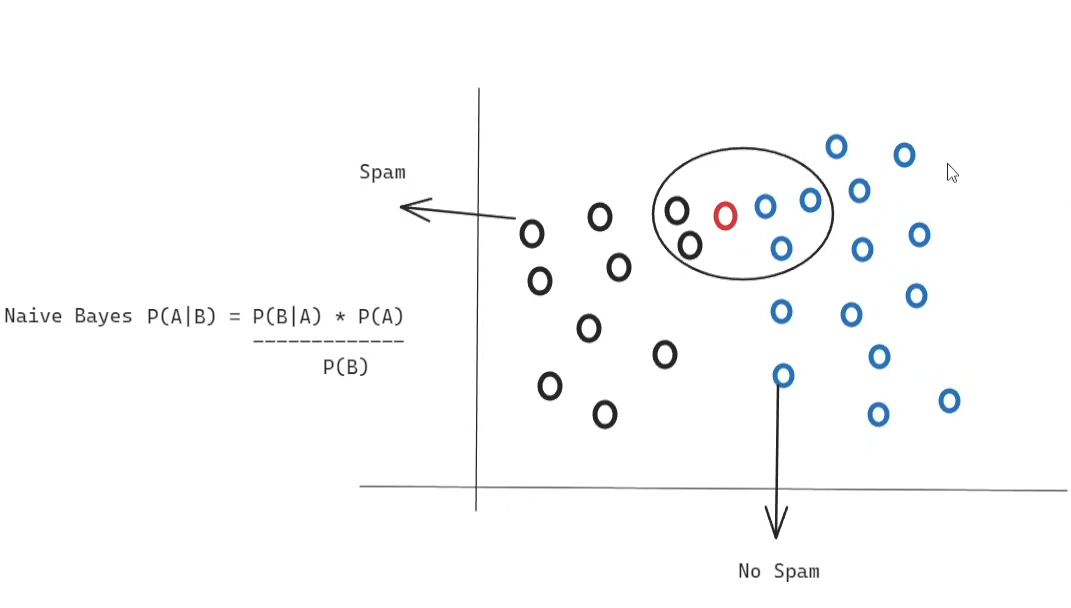

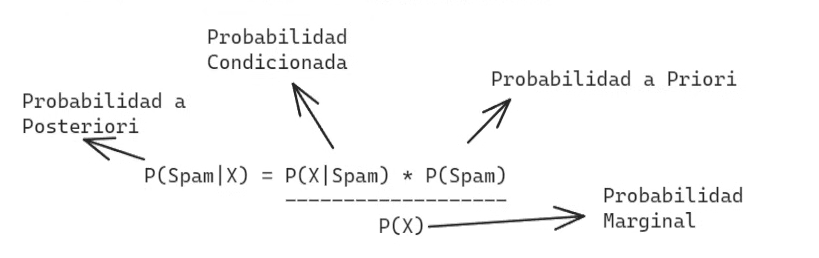

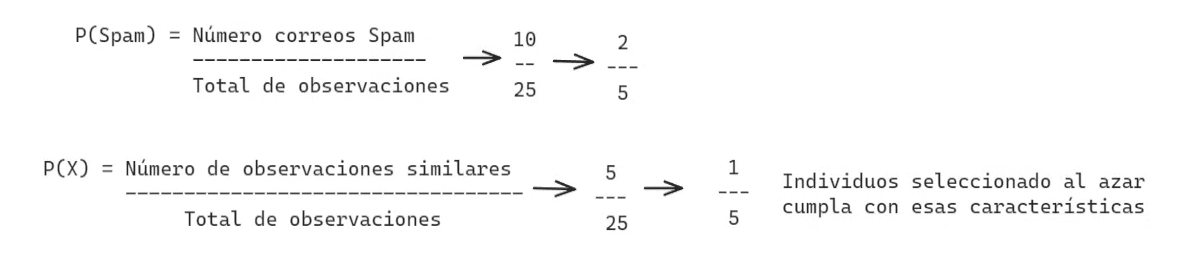



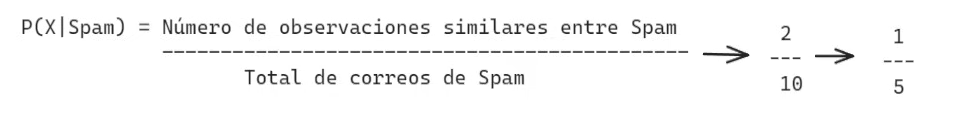

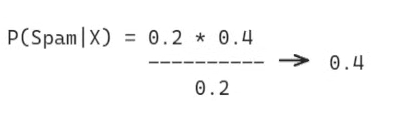

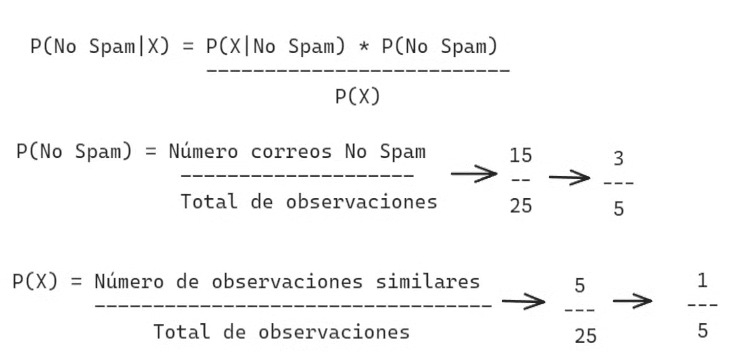

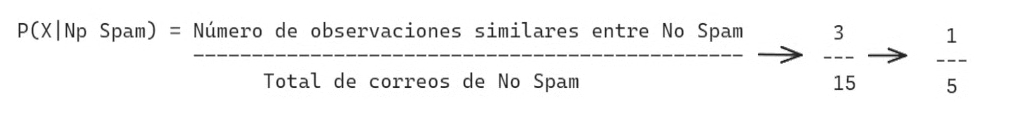

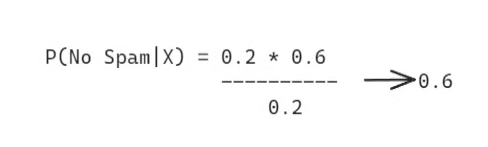

In [ ]:
import pandas as pd

#cargar conjunto y sacar variables dep e indep
data = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')
X = data.iloc[:, [2, 3]]
y = data.iloc[:, -1].values
gender = data[['Gender']]

#manejo de la variable categórica (Gender)
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(gender)
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns = cat_encoder.get_feature_names_out())
data1 = pd.concat([X, encoded_df], axis = 1)

#division en train y test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


#escalado de variables
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)


In [ ]:
from sklearn.naive_bayes import GaussianNB
cls = GaussianNB()
cls.fit(X_train, y_train)

y_pred = cls.predict(X_test)

from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import precision_score, recall_score
print('Precision:',precision_score(y_test, y_pred))
print('Recall:',recall_score(y_test, y_pred))

from sklearn.metrics import f1_score
print('F1:',f1_score(y_test, y_pred))

[[65  3]
 [ 7 25]]
Precision: 0.8928571428571429
Recall: 0.78125
F1: 0.8333333333333334


In [ ]:
# vemos que en este caso tenemos 10 errores (7+3) igual que con SVR kernel
# lineal (8+2 = 10)
# sin embargo, vemos que las métricas son mejores en cuanto a memoria (0.75) y F1 (0.8275)
# aunque perdemos algo de precisión (0.923)

##Árboles de decisión

Para clasificación

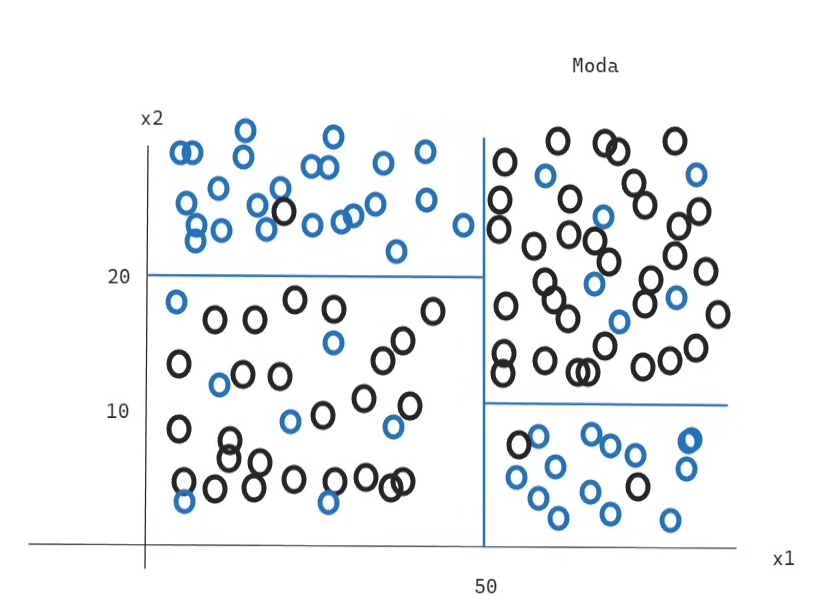

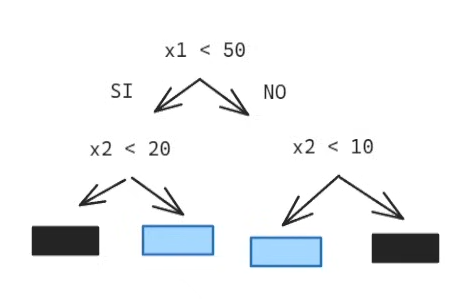

Ventajas y desventajas

Ventajas

* Interpretabilidad: Fácil de entender y visualizar, permitiendo la interpretación de resultados.



* Manejo de datos mixtos: Puede manejar datos categóricos y numéricos.
No requiere normalización de los datos.


Desventajas

* Sobreajuste: Puede ser propenso al sobreajuste.
* Inestabilidad: Pequeñas variaciones en los datos pueden resultar en árboles diferentes, lo que los hace inestables.
* Sensible a datos ruidosos.

In [8]:
import pandas as pd

#cargar conjunto y sacar variables dep e indep
data = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')
X = data.iloc[:, [2, 3]]
y = data.iloc[:, -1].values
gender = data[['Gender']]

#manejo de la variable categórica (Gender)
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(gender)
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns = cat_encoder.get_feature_names_out())
data1 = pd.concat([X, encoded_df], axis = 1)

#division en train y test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


#escalado de variables --> No es necesario

In [17]:
from sklearn.tree import DecisionTreeClassifier
cls = DecisionTreeClassifier()
cls.fit(X_train, y_train)

y_pred = cls.predict(X_test)

from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import precision_score, recall_score
print('Precision:',precision_score(y_test, y_pred))
print('Recall:',recall_score(y_test, y_pred))

from sklearn.metrics import f1_score
print('F1:',f1_score(y_test, y_pred))

[[62  6]
 [ 4 28]]
Precision: 0.8235294117647058
Recall: 0.875
F1: 0.8484848484848485


In [ ]:
# Vemos que el árbol proporciona una mejor memoria y una peor precisión
# vemos que algoritmo de arboles aleatorios es bueno y rápido en pequeños conjuntos de datos,
#presentando una buena clasificación y memoria aunque algo bajo en precisión

##Bosques Aleatorios

Para clasificación

Un bosque aleatorio es un conjunto de árboles de decisión individuales entrenados en diferentes subconjuntos de datos y características. En el contexto de clasificación, cada árbol en el bosque realiza una predicción y la clase que recibe más votos se selecciona como la predicción final del bosque.

Los bosques aleatorios son útiles en situaciones donde:

* Se necesita alta precisión y generalización.
* Conjuntos de datos complejos.
* Interpretación intermedia.

Ventajas y desventajas

**Ventajas**

* Alta precisión
* Robustez: Es robusto ante sobreajuste debido al muestro aleatorio y la combinación de múltiples árboles
* Manejo de datos desbalanceados: Puede manejar problemas de clasificación desbalanceada de manera efectiva


**Desventajas**

* Menos interpretable que un solo árbol.
* Menos eficiente en conjuntos de datos pequeños.
* Tiempo de entrenamiento: Puede llevar más tiempo que el entrenamiento de un solo árbol, especialmente en conjuntos de datos grandes.

In [18]:
import pandas as pd

#cargar conjunto y sacar variables dep e indep
data = pd.read_csv('/content/sample_data/Social_Network_Ads.csv')
X = data.iloc[:, [2, 3]]
y = data.iloc[:, -1].values
gender = data[['Gender']]

#manejo de la variable categórica (Gender)
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
data_cat_1hot = cat_encoder.fit_transform(gender)
encoded_df = pd.DataFrame(data_cat_1hot.toarray(), columns = cat_encoder.get_feature_names_out())
data1 = pd.concat([X, encoded_df], axis = 1)

#division en train y test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


#escalado de variables --> No es necesario

In [21]:
from sklearn.ensemble import RandomForestClassifier
cls = RandomForestClassifier(n_estimators=40)
cls.fit(X_train, y_train)

y_pred = cls.predict(X_test)

from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import precision_score, recall_score
print('Precision:',precision_score(y_test, y_pred))
print('Recall:',recall_score(y_test, y_pred))

from sklearn.metrics import f1_score
print('F1:',f1_score(y_test, y_pred))

[[64  4]
 [ 4 28]]
Precision: 0.875
Recall: 0.875
F1: 0.875


In [ ]:
# vemos que incrementa un poco la precisión sin pérdida de memoria --> Mejora el F1
# PUEDE PARECER QUE GANAMOS RESPECTO AL BOSQUE PERO, ANTE UNA CANTIDAD DE DATOS ELEVADA, EL ALGORITMO
# DE RANDOM FOREST PUEDE SER MÁS LENTO